In [44]:
%load_ext autoreload
%autoreload 2
import os

import matplotlib.pyplot as plt
import numpy as np
import unyt as u
from dev.datapaths import TDE_PARAMETERS
from matplotlib.lines import Line2D

import dev
import richio

DATADIR = "/home/hey4/rich_tde/data/processed/SimpleTimeseries"
RUN_LABELS = {
    "1e4": r"10$^4$",
    "1e5": r"10$^5$",
    "1e6": r"10$^6$",
    "ss24": r"10$^6$ (SS24)",
    "1e4midres": r"10$^4$ (mid res)",
    "1e4lowres": r"10$^4$ (low res)",
    "1e4streamhires": r"10$^4$ (stream hi res)",
    "1e4streamhires2": r"10$^4$ (stream hi res 2)",
}
RUN_COLORS = {run: f"C{i}" for i, run in enumerate(RUN_LABELS)}
REGION_STYLES = {"pericenter side": "-", "stream side": "--"}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
def load_power(run):
    """Time [t_fb], pericenter-side and stream-side dissipation power [Delta E_c / t_fb] from 0.1 t_fb."""
    table = np.loadtxt(os.path.join(DATADIR, f"Ediss-t-{run}-final.txt"))
    table = table[np.argsort(table[:, 1])]
    table = table[table[:, 2] >= 0.1]
    m_bh, m_star, r_star = TDE_PARAMETERS[run]
    tde = dev.TDEBasics(
        Mbh=m_bh * richio.units.mscale,
        Mstar=m_star * richio.units.mscale,
        Rstar=r_star * richio.units.lscale,
    )
    energy_spread = u.G * tde.Mbh * tde.Mstar / (8 * tde.r_p)
    power = u.unyt_array(
        table[:, 3:6].T,
        "code_mass*code_length**2/code_time**3",
        registry=richio.units.registry,
    )
    pericenter, outgoing, incoming = (power * tde.t_fb / energy_spread).to_value(
        "dimensionless"
    )
    return table[:, 2], pericenter, outgoing + incoming

In [46]:
def plot_ediss(runs):
    fig, (ax, ax_ratio) = plt.subplots(
        2,
        1,
        figsize=(6, 5),
        dpi=300,
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08},
    )
    for run in runs:
        time, pericenter, stream = load_power(run)
        late = time >= (0.7 if run == "ss24" else 0)
        for power, style in zip((pericenter, stream), REGION_STYLES.values()):
            ax.plot(time[late], power[late], color=RUN_COLORS[run], linestyle=style)
        ax_ratio.plot(time, pericenter / stream, color=RUN_COLORS[run])

    ax.set_ylabel(r"$\dot{E}_\mathrm{diss}/\Delta E_c\,[1/t_\mathrm{fb}]$")
    ax.set_yscale("log")
    ax.set_ylim(1e-9, 1)
    region_handles = [
        Line2D([], [], color="k", linestyle=style, label=region)
        for region, style in REGION_STYLES.items()
    ]
    run_handles = [
        Line2D([], [], color=RUN_COLORS[run], label=RUN_LABELS[run]) for run in runs
    ]
    ax.add_artist(
        ax.legend(
            handles=region_handles,
            loc="lower right",
        )
    )
    ax.legend(
        handles=run_handles,
        title=r"$M_\bullet\,[M_\odot]$",
        loc="upper left",
    )

    ax_ratio.set_xlabel(r"$t\,[t_\mathrm{fb}]$")
    ax_ratio.set_ylabel("pericenter / stream")
    ax_ratio.set_yscale("log")
    ax_ratio.set_ylim(1e-1, 10**2.5)
    fig.align_ylabels()
    return fig

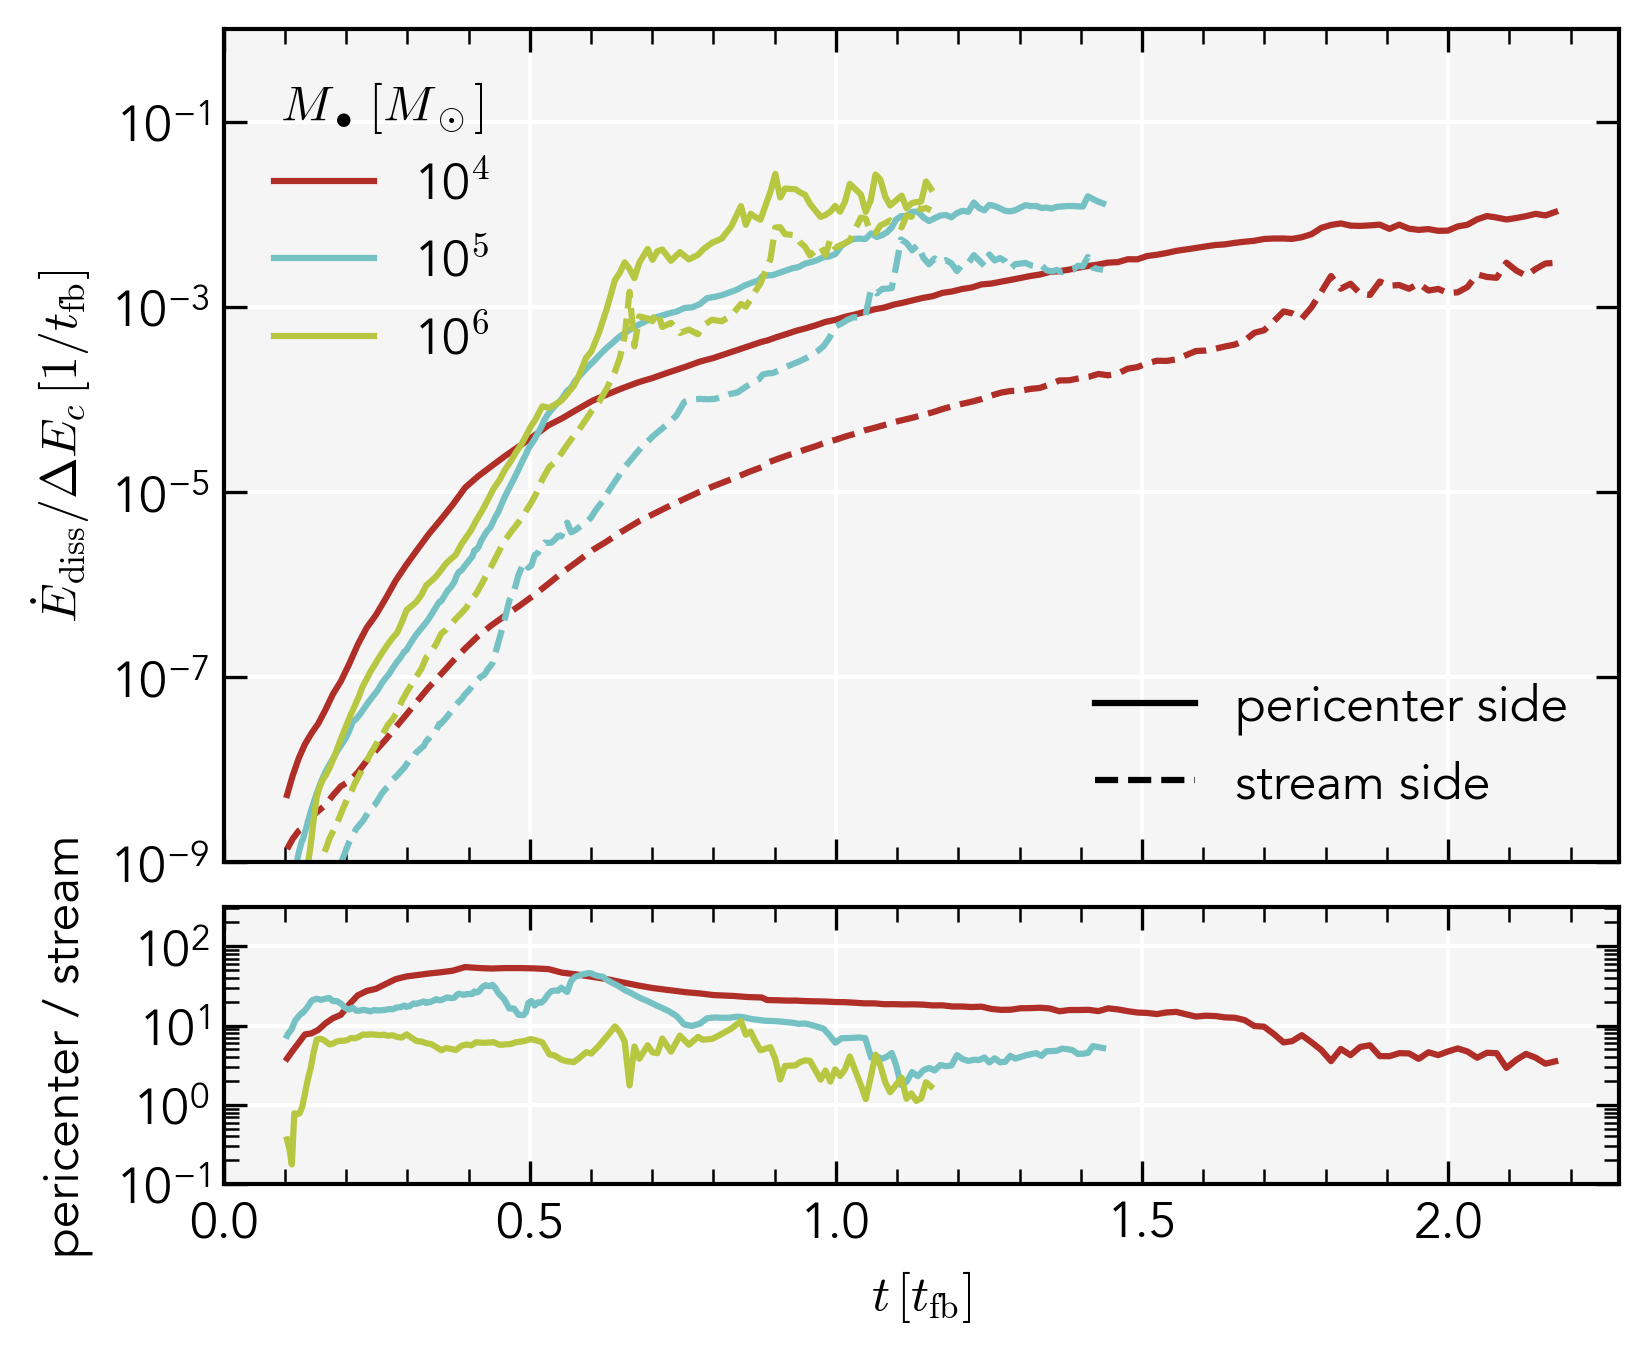

In [47]:
fig = plot_ediss(["1e4", "1e5", "1e6"])
fig.savefig("/home/hey4/rich_tde/reports/shockpaper/figures/Ediss-t.pdf")
plt.show()

/tmp/ipykernel_3126480/3930366006.py:15: RuntimeWarning: invalid value encountered in divide
  ax_ratio.plot(time, pericenter / stream, color=RUN_COLORS[run])


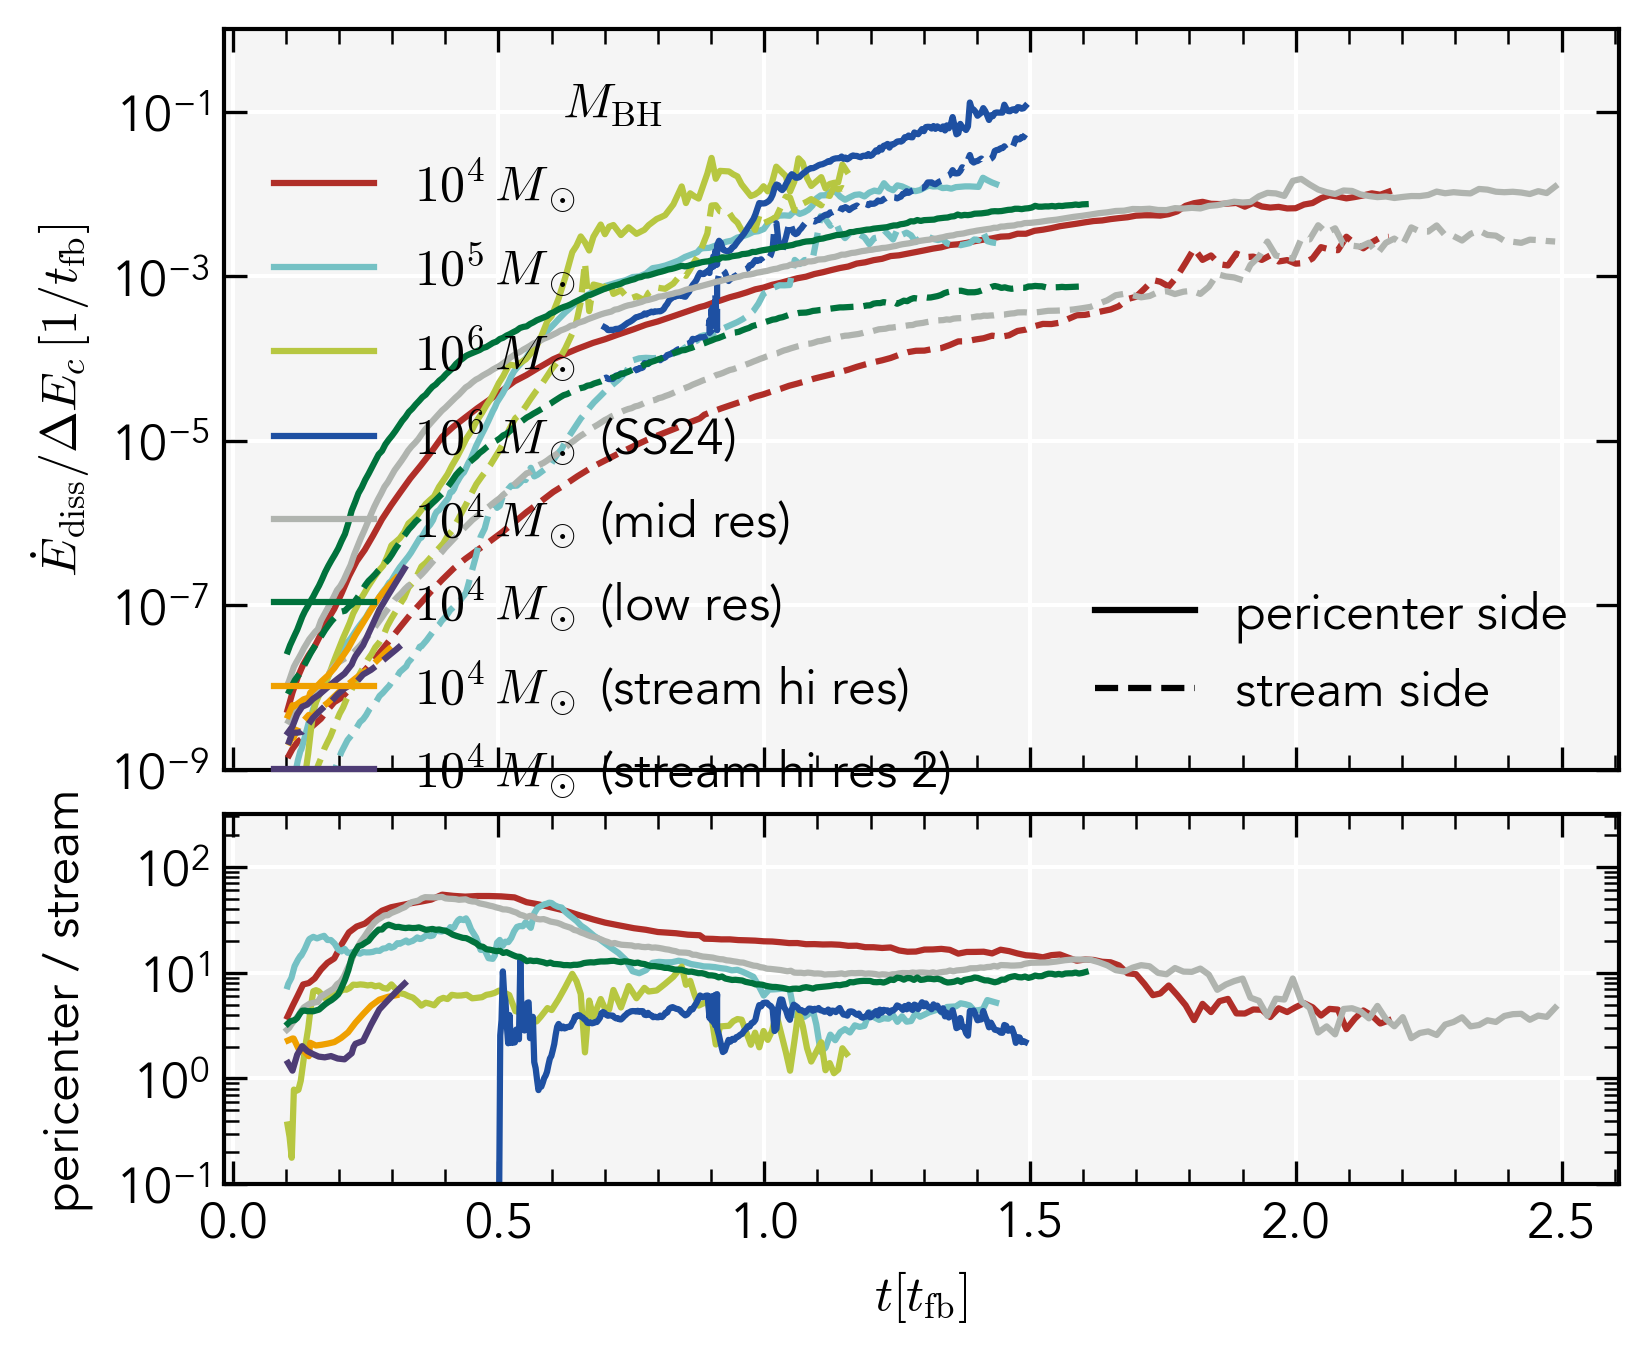

In [40]:
plot_ediss(RUN_LABELS)
plt.show()